# 01 · Exploración y modelos

Este notebook es el espacio de **experimentación**. Aquí se prueba el método paso a paso; lo que funciona se pasa a `src/costos/` como código con pruebas, que es lo único que corre en producción.

**Dónde correrlo**

- En local: `make setup` y abre el archivo con Jupyter o VS Code.
- En Colab Enterprise: súbelo al proyecto de experimentación, cambia `ORIGEN` a la ruta `gs://` de los datos y ejecuta todo.

In [1]:
import warnings
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import coint

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (11, 4.5)

# En local: la carpeta Datos del repositorio.
# En Colab Enterprise: la ruta de los datos de producción, en solo lectura,
# por ejemplo "gs://PROYECTO-PROD-crudos/datos".
ORIGEN = "../Datos"

## Paso 1. Carga y limpieza

Cada archivo trae su propio formato:

- `X.csv`: separador coma, fechas ISO y orden descendente.
- `Y.csv`: separador punto y coma, decimales con coma, fechas día/mes/año y un BOM al inicio.
- `Z.csv`: columnas invertidas, el precio va antes que la fecha.
- `historico_equipos.csv`: materias primas y equipos en días hábiles.

Las validaciones detienen el análisis si algo no cuadra. En producción son las **compuertas de calidad** del pipeline.

In [2]:
x = pd.read_csv(f"{ORIGEN}/X.csv", parse_dates=["Date"])
y = pd.read_csv(f"{ORIGEN}/Y.csv", sep=";", decimal=",", encoding="utf-8-sig")
y["Date"] = pd.to_datetime(y["Date"], format="%d/%m/%Y")
z = pd.read_csv(f"{ORIGEN}/Z.csv", parse_dates=["Date"])
eq = pd.read_csv(f"{ORIGEN}/historico_equipos.csv", parse_dates=["Date"])

series = {
    "X": x.set_index("Date")["Price"].sort_index(),
    "Y": y.set_index("Date")["Price"].sort_index(),
    "Z": z.set_index("Date")["Price"].sort_index(),
}
eq = eq.set_index("Date").sort_index()
eq.columns = [c.replace("Price_", "") for c in eq.columns]

for nombre, s in series.items():
    assert s.index.is_unique, f"{nombre}: fechas duplicadas"
    assert s.notna().all(), f"{nombre}: valores faltantes"
    assert (s > 0).all(), f"{nombre}: precios no positivos"
for col in ["X", "Y", "Z"]:
    comun = eq.index.intersection(series[col].index)
    assert (eq.loc[comun, col] - series[col].loc[comun]).abs().max() < 0.01, f"{col} no coincide"

pd.DataFrame(
    {n: {"filas": len(s), "desde": s.index.min().date(), "hasta": s.index.max().date()}
     for n, s in {**series, "historico": eq}.items()}
).T

,filas,desde,hasta
X,9144,1988-06-27,2024-04-04
Y,4485,2006-07-11,2023-09-12
Z,3565,2010-01-01,2023-08-31
historico,3530,2010-01-04,2023-08-31


## Paso 2. Frecuencia mensual

El proyecto planea por mes y el ruido diario esconde las relaciones. Se promedia cada serie por mes y la fecha queda en el día 1.

In [3]:
mensual = eq.resample("MS").mean().dropna()
print(f"{len(mensual)} meses, de {mensual.index.min():%Y-%m} a {mensual.index.max():%Y-%m}")
mensual.tail()

164 meses, de 2010-01 a 2023-08


,X,Y,Z,Equipo1,Equipo2
Date,,,,,
2023-04-01,83.369,603.886,2336.763,503.402,1009.561
2023-05-01,75.695,550.594,2271.587,457.469,964.018
2023-06-01,74.979,541.776,2180.739,449.976,931.185
2023-07-01,80.160,554.358,2152.012,460.872,929.810
2023-08-01,85.104,556.304,2133.022,461.035,927.661


## Paso 3. Mirar los datos antes de modelar

En base 100 todas las series arrancan igual y se ve cuáles se mueven juntas. Los picos y caídas grandes son buenos puntos para investigar qué pasó en el mercado.

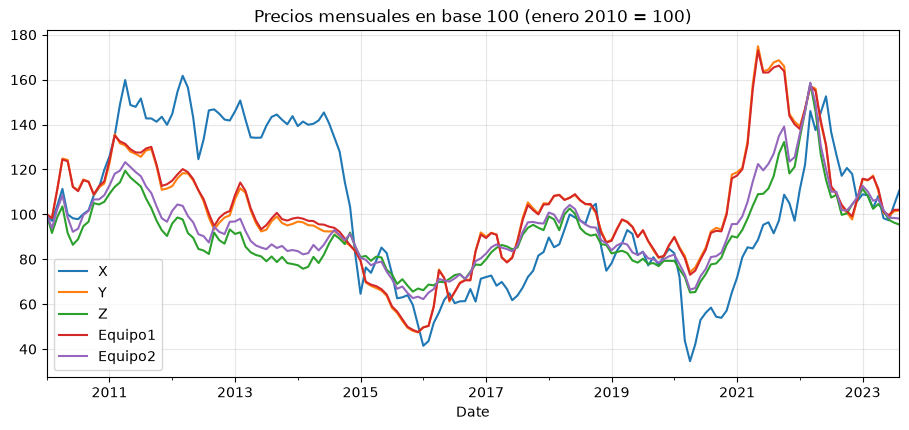

In [4]:
(mensual / mensual.iloc[0] * 100).plot(title="Precios mensuales en base 100 (enero 2010 = 100)")
plt.grid(alpha=0.3)
plt.show()

## Paso 4. Correlaciones en niveles y en variaciones

Dos series con tendencia pueden correlacionar sin tener relación. Si la correlación es alta en niveles pero baja en variaciones, hay que sospechar; si es alta en ambas, hay señal. Se compara también diaria contra mensual.

In [5]:
def tabla_correlaciones(df):
    columnas = ["Equipo1", "Equipo2"]
    niveles = df.corr().loc[columnas, ["X", "Y", "Z"]]
    variaciones = np.log(df).diff().dropna().corr().loc[columnas, ["X", "Y", "Z"]]
    return pd.concat({"niveles": niveles, "variaciones": variaciones}, axis=1)

pd.concat({"diaria": tabla_correlaciones(eq), "mensual": tabla_correlaciones(mensual)}).round(2)

niveles             variaciones            
                      X     Y     Z           X     Y     Z
diaria  Equipo1    0.52  1.00  0.84        0.03  0.38  0.02
        Equipo2    0.53  0.91  0.98        0.07  0.10  0.40
mensual Equipo1    0.53  1.00  0.85        0.33  1.00  0.44
        Equipo2    0.53  0.92  0.99        0.50  0.65  0.96

## Paso 5. Rezagos

¿Reacciona el equipo a la materia prima con meses de retraso? Promediar por mes crea algo de correlación en el rezago 1 por sí solo, así que un rezago solo cuenta si además mejora el error fuera de muestra.

In [6]:
variaciones = np.log(mensual).diff().dropna()
filas = []
for equipo in ["Equipo1", "Equipo2"]:
    for mp in ["X", "Y", "Z"]:
        for k in range(4):
            filas.append({"equipo": equipo, "materia_prima": mp, "rezago": k,
                          "correlacion": variaciones[equipo].corr(variaciones[mp].shift(k))})
pd.DataFrame(filas).pivot_table(index=["equipo", "materia_prima"], columns="rezago", values="correlacion").round(2)

rezago                    0     1     2     3
equipo  materia_prima                        
Equipo1 X              0.33  0.28  0.06 -0.13
        Y              1.00  0.43 -0.05 -0.06
        Z              0.44  0.41  0.15 -0.05
Equipo2 X              0.50  0.25  0.05 -0.11
        Y              0.65  0.27 -0.03 -0.04
        Z              0.96  0.32  0.03 -0.01

## Paso 6. Una regresión por equipo, elegida fuera de muestra

Este es el corazón del análisis. Se prueban todas las combinaciones de materias primas, se entrena hasta agosto de 2021 y se mide el error en los 24 meses siguientes. **El corte es por fecha, nunca al azar**, para no meter información del futuro en el entrenamiento.

Regla de decisión: la combinación con menos variables cuyo MAPE de prueba quede dentro del 10 % del mejor.

In [7]:
def mape(real, pred):
    return float((abs(real - pred) / real).mean() * 100)

train, test = mensual.loc[:"2021-08"], mensual.loc["2021-09":]
filas = []
for equipo in ["Equipo1", "Equipo2"]:
    for k in (1, 2, 3):
        for variables in combinations(["X", "Y", "Z"], k):
            v = list(variables)
            m = sm.OLS(train[equipo], sm.add_constant(train[v])).fit()
            pred = m.predict(sm.add_constant(test[v], has_constant="add"))
            filas.append({"equipo": equipo, "variables": "+".join(v), "n": k,
                          "r2_train": m.rsquared, "mape_test": mape(test[equipo], pred)})
seleccion = pd.DataFrame(filas).sort_values(["equipo", "mape_test"])

elegidas = {}
for equipo, tabla in seleccion.groupby("equipo"):
    candidatas = tabla[tabla["mape_test"] <= tabla["mape_test"].min() * 1.10]
    elegidas[equipo] = candidatas.sort_values(["n", "mape_test"]).iloc[0]["variables"].split("+")
print("Variables elegidas:", elegidas)
seleccion.round(4)

Variables elegidas: {'Equipo1': ['X', 'Y'], 'Equipo2': ['X', 'Y', 'Z']}


,equipo,variables,n,r2_train,mape_test
6,Equipo1,X+Y+Z,3,1.000,0.336
3,Equipo1,X+Y,2,1.000,0.338
1,Equipo1,Y,1,0.998,0.505
5,Equipo1,Y+Z,2,0.998,0.593
0,Equipo1,X,1,0.284,14.645
4,Equipo1,X+Z,2,0.750,15.016
2,Equipo1,Z,1,0.735,16.260
13,Equipo2,X+Y+Z,3,1.000,0.179
12,Equipo2,Y+Z,2,0.997,0.493
11,Equipo2,X+Z,2,0.973,3.027


### Diagnósticos del modelo final

Se ajusta cada modelo con todos los datos y se revisa:

| Diagnóstico | Qué buscas |
| --- | --- |
| p-valor de cada coeficiente | Menor a 0.05 |
| Signo del coeficiente | Positivo: si sube la materia prima, sube el equipo |
| Errores HAC | Corrigen la confianza cuando los residuos se parecen mes a mes |
| Cointegración | p menor a 0.05: la relación de largo plazo es real |
| VIF | Menor a 5: las variables no se pisan entre sí |

In [8]:
for equipo, variables in elegidas.items():
    X_ = sm.add_constant(mensual[variables])
    final = sm.OLS(mensual[equipo], X_).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    p_coint = coint(mensual[equipo], mensual[variables], return_results=False)[1]
    vif = {c: round(float(variance_inflation_factor(X_.to_numpy(), i)), 2)
           for i, c in enumerate(X_.columns) if c != "const"} if len(variables) > 1 else {variables[0]: 1.0}
    print(f"=== {equipo}: {variables} | R² {final.rsquared:.4f} | cointegración p={p_coint:.4f} | VIF {vif}")
    print(final.summary().tables[1], "\n")

=== Equipo1: ['X', 'Y'] | R² 0.9997 | cointegración p=0.0000 | VIF {'X': 1.33, 'Y': 1.33}
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0453      0.591     -0.077      0.939      -1.204       1.113
X              0.1982      0.008     24.149      0.000       0.182       0.214
Y              0.8003      0.002    494.875      0.000       0.797       0.803

=== Equipo2: ['X', 'Y', 'Z'] | R² 0.9997 | cointegración p=0.0000 | VIF {'X': 1.35, 'Y': 3.82, 'Z': 3.73}
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6357      1.058      0.601      0.548      -1.437       2.709
X              0.3353      0.009     36.803      0.000       0.317       0.353
Y              0.3353      0.003    120.195      0.000       0.330       0.341
Z            

## Conclusiones del notebook

- **Diaria contra mensual.** En datos diarios las correlaciones de las variaciones son bajas porque el ruido de cada día domina. Al promediar por mes la relación aparece con claridad: por eso se trabaja en frecuencia mensual.
- **Equipo 1 se explica con X y Y.** Ese modelo tiene un error fuera de muestra de 0.34 %. Agregar Z apenas cambia el error, de 0.338 % a 0.336 %, así que Z es ruido para este equipo. X tiene correlación simple baja y aun así su coeficiente es significativo: la correlación sola no basta para elegir variables.
- **Equipo 2 necesita las tres materias primas.** Con cualquier combinación más corta el error sube de 0.18 % a 0.49 % o más.
- **Diagnósticos en orden.** Ambos modelos están cointegrados, sus coeficientes son positivos y significativos, y el VIF queda por debajo de 5.

El siguiente notebook usa estas variables para pronosticar con intervalos. El pipeline de producción recalcula la selección en cada corrida con la misma regla.